In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
raw_scores = pd.DataFrame({
    "Player": ["Nova", "Pixel", "Echo", "Nova", "Pixel", "Echo", "Nova"],
    "Round":  [1, 1, 1, 2, 2, 2, 1],
    "Score":  [85, 90, None, 75, 88, 65, 85]
})

raw_scores

,Player,Round,Score
0,Nova,1,85.0
1,Pixel,1,90.0
2,Echo,1,NaN
3,Nova,2,75.0
4,Pixel,2,88.0
5,Echo,2,65.0
6,Nova,1,85.0


In [3]:
raw_scores.isna().sum()

Player    0
Round     0
Score     1
dtype: int64

In [4]:
clean_scores = raw_scores.drop_duplicates().dropna(subset="Score")
clean_scores

,Player,Round,Score
0,Nova,1,85.0
1,Pixel,1,90.0
3,Nova,2,75.0
4,Pixel,2,88.0
5,Echo,2,65.0


In [5]:
summary = clean_scores.groupby("Player").agg(
    Average=("Score", "mean"),
    Lowest=("Score", "min"),
    Highest=("Score", "max"),
    Games=("Score", "count")
).sort_values("Average", ascending=False)
summary

,Average,Lowest,Highest,Games
Player,,,,
Pixel,89.0,88.0,90.0,2
Nova,80.0,75.0,85.0,2
Echo,65.0,65.0,65.0,1


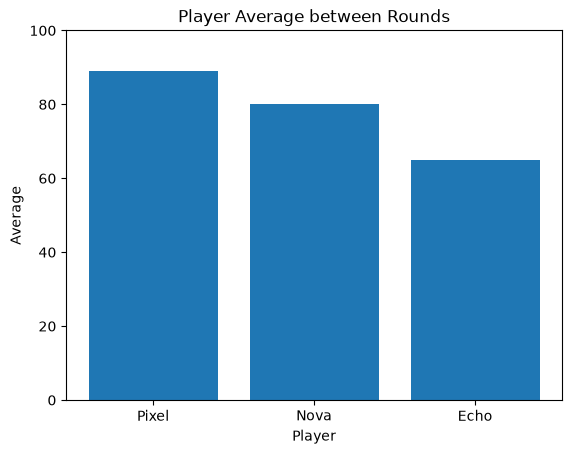

In [6]:
plt.bar(summary.index, summary["Average"])

plt.xlabel("Player")
plt.ylabel("Average")
plt.ylim(0, 100)
plt.title("Player Average between Rounds")
plt.show()

! It's important to note that echos score is incomplete !
- Pixel has the highest observed average: 89.
- Nova averages 80 across two recorded rounds.
- Echo’s average uses only one score, so the comparison is incomplete.

In [7]:
clean_scores.to_csv("clean_scores.csv", index=False)
summary.to_csv("player_summary.csv")